In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()   # a file picker will appear; choose your survey file
file_name = list(uploaded.keys())[0]
print("Uploaded file:", file_name)

Saving Make Pune Metro Better!.csv to Make Pune Metro Better!.csv
Uploaded file: Make Pune Metro Better!.csv


In [ ]:
# Use the line that matches your file type (delete the other one)

df = pd.read_csv(file_name)        # if CSV
# df = pd.read_excel(file_name)    # if Excel (.xlsx)

print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (673, 17)


In [ ]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

df.head()

,Timestamp,What is your age group?,How often do you use Pune Metro?,What is your main reason for using Pune Metro?,"1. It is easy for me to reach a Pune Metro station from my home, workplace, college, or other destination.",2. Pune Metro stations are accessible and convenient for people of different ages and abilities.,3. I feel safe while travelling in Pune Metro.,"4. Information such as routes, timings, announcements, and station signs is clear and easy to understand.",5. Pune Metro fares are affordable for regular travel.,6. Pune Metro services are punctual and reliable.,7. Pune Metro provides a comfortable travelling experience.,8. Pune Metro trains and stations are clean and well maintained.,"9. Pune Metro is well connected with other modes of transport such as buses, auto-rickshaws, and other public transport.",10. Pune Metro makes it easier for people to choose public transport instead of private vehicles.,"11. Pune Metro's services and infrastructure support the idea of safe, affordable, accessible, and sustainable public transport.","12. Overall, how would you rate Pune Metro's contribution to sustainable urban transportation in Pune?",13. What is the one improvement that would make Pune Metro more sustainable and useful for people in Pune?
0,2026/08/12 2:10:51 pm GMT+5:30,19–25,Daily,Work,3,3,3,3,4,3,4,3,3,3,3,3 = Moderate,NaN
1,2026/08/12 2:12:50 pm GMT+5:30,19–25,Daily,College / School,5,5,5,5,4,3,4,4,4,4,4,4 = High,NaN
2,2026/08/12 2:16:00 pm GMT+5:30,19–25,A few times a month,College / School,3,3,3,3,3,3,3,3,3,3,3,3 = Moderate,Increase the number of parking slots
3,2026/08/12 2:16:51 pm GMT+5:30,19–25,A few times a month,Leisure / Entertainment,2,5,5,5,5,4,4,4,3,3,4,4 = High,They should increase the stations in pune \n
4,2026/08/12 2:18:10 pm GMT+5:30,19–25,Rarely,Leisure / Entertainment,1,3,4,4,5,4,4,4,3,3,4,2 = Low,build 1 to 2 lines more faster


In [ ]:
for i, col in enumerate(df.columns):
    print(i, "|", col)

0 | Timestamp
1 | What is your age group? 
2 |   How often do you use Pune Metro?  
3 | What is your main reason for using Pune Metro?  
4 | 1. It is easy for me to reach a Pune Metro station from my home, workplace, college, or other destination.  
5 | 2. Pune Metro stations are accessible and convenient for people of different ages and abilities.  
6 |  3. I feel safe while travelling in Pune Metro.  
7 | 4.  Information such as routes, timings, announcements, and station signs is clear and easy to understand.  
8 | 5. Pune Metro fares are affordable for regular travel.  
9 | 6. Pune Metro services are punctual and reliable.  
10 | 7. Pune Metro provides a comfortable travelling experience.  
11 | 8. Pune Metro trains and stations are clean and well maintained. 
12 | 9.  Pune Metro is well connected with other modes of transport such as buses, auto-rickshaws, and other public transport.  
13 | 10. Pune Metro makes it easier for people to choose public transport instead of private veh

In [ ]:
df.info()
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nTotal duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 673 entries, 0 to 672
Data columns (total 17 columns):
 #   Column                                                                                                                             Non-Null Count  Dtype 
---  ------                                                                                                                             --------------  ----- 
 0   Timestamp                                                                                                                          673 non-null    object
 1   What is your age group?                                                                                                            673 non-null    object
 2     How often do you use Pune Metro?                                                                                                 673 non-null    object
 3   What is your main reason for using Pune Metro?                                                 

In [ ]:
target_col = df.columns[15]

print("TARGET column unique values and counts:")
print(df[target_col].value_counts(dropna=False))

# Confirm Q1-Q11 only contain values 1-5
likert_cols = df.columns[4:15]
for col in likert_cols:
    print(sorted(df[col].unique()), "|", col[:50])

# Quick look at the context columns
for col in df.columns[1:4]:
    print("\n", col.strip())
    print(df[col].value_counts(dropna=False))

TARGET column unique values and counts:
12. Overall, how would you rate Pune Metro's contribution to sustainable urban transportation in Pune?  
2 = Low          257
1 = Very Low     245
4 = High          66
3 = Moderate      57
5 = Very High     48
Name: count, dtype: int64
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | 1. It is easy for me to reach a Pune Metro station
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | 2. Pune Metro stations are accessible and convenie
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] |  3. I feel safe while travelling in Pune Metro.  
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | 4.  Information such as routes, timings, announcem
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | 5. Pune Metro fares are affordable for regular tra
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | 6. Pune Metro services are punctual and reliable. 
[np.int64(1

In [ ]:
target_col = df.columns[15]

# Take the first character (the digit) and convert to integer
df["overall_perception"] = df[target_col].str.strip().str[0].astype(int)

# Verify: the original label and new number should match row by row
print(pd.crosstab(df[target_col].str.strip(), df["overall_perception"]))

overall_perception                                                                  1  \
12. Overall, how would you rate Pune Metro's contribution to sustainable urba...        
1 = Very Low                                                                      245   
2 = Low                                                                             0   
3 = Moderate                                                                        0   
4 = High                                                                            0   
5 = Very High                                                                       0   

overall_perception                                                                  2  \
12. Overall, how would you rate Pune Metro's contribution to sustainable urba...        
1 = Very Low                                                                        0   
2 = Low                                                                           257   
3 = Moderate        

In [ ]:
short_names = {
    df.columns[4]:  "last_mile_connectivity",
    df.columns[5]:  "accessibility",
    df.columns[6]:  "safety",
    df.columns[7]:  "information",
    df.columns[8]:  "affordability",
    df.columns[9]:  "reliability",
    df.columns[10]: "comfort",
    df.columns[11]: "cleanliness",
    df.columns[12]: "pt_integration",
    df.columns[13]: "sustainable_mobility",
    df.columns[14]: "sdg_alignment",
    df.columns[1]:  "age_group",
    df.columns[2]:  "usage_frequency",
    df.columns[3]:  "main_reason",
    df.columns[16]: "improvement_text",
}

# Save the mapping so the original question wording is documented
question_lookup = {new: old.strip() for old, new in short_names.items()}

df = df.rename(columns=short_names)
df.columns

Index(['Timestamp', 'age_group', 'usage_frequency', 'main_reason',
       'last_mile_connectivity', 'accessibility', 'safety', 'information',
       'affordability', 'reliability', 'comfort', 'cleanliness',
       'pt_integration', 'sustainable_mobility', 'sdg_alignment',
       '12. Overall, how would you rate Pune Metro's contribution to sustainable urban transportation in Pune?  ',
       'improvement_text', 'overall_perception'],
      dtype='object')

In [ ]:
print("Shape:", df.shape)
print("\nTarget data type:", df["overall_perception"].dtype)
print("\nTarget value counts:")
print(df["overall_perception"].value_counts().sort_index())

num_cols = ["last_mile_connectivity", "accessibility", "safety", "information",
            "affordability", "reliability", "comfort", "cleanliness",
            "pt_integration", "sustainable_mobility", "sdg_alignment",
            "overall_perception"]
print("\nMissing in numeric columns:", df[num_cols].isnull().sum().sum())

Shape: (673, 18)

Target data type: int64

Target value counts:
overall_perception
1    245
2    257
3     57
4     66
5     48
Name: count, dtype: int64

Missing in numeric columns: 0


In [ ]:
mapping = pd.DataFrame({
    "variable": ["last_mile_connectivity", "accessibility", "safety", "information",
                 "affordability", "reliability", "comfort", "cleanliness",
                 "pt_integration", "sustainable_mobility", "sdg_alignment"],
    "survey_item": ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7", "Q8", "Q9", "Q10", "Q11"],
    "sdg_dimension": ["Access / last-mile connectivity", "Accessibility", "Safety",
                      "Information availability", "Affordability", "Reliability",
                      "Comfort", "Cleanliness", "Public transport integration",
                      "Sustainable mobility", "SDG 11.2 alignment (summary item)"],
})
mapping

,variable,survey_item,sdg_dimension
0,last_mile_connectivity,Q1,Access / last-mile connectivity
1,accessibility,Q2,Accessibility
2,safety,Q3,Safety
3,information,Q4,Information availability
4,affordability,Q5,Affordability
5,reliability,Q6,Reliability
6,comfort,Q7,Comfort
7,cleanliness,Q8,Cleanliness
8,pt_integration,Q9,Public transport integration
9,sustainable_mobility,Q10,Sustainable mobility


In [ ]:
predictors = mapping["variable"].tolist()

corr_with_target = df[predictors + ["overall_perception"]].corr()["overall_perception"].drop("overall_perception")
print(corr_with_target.sort_values(ascending=False).round(3))

comfort                   0.531
reliability               0.524
sustainable_mobility      0.521
safety                    0.492
sdg_alignment             0.491
pt_integration            0.486
accessibility             0.485
affordability             0.484
information               0.465
last_mile_connectivity    0.451
cleanliness               0.426
Name: overall_perception, dtype: float64


In [ ]:
corr_matrix = df[predictors].corr().round(2)
print(corr_matrix["sdg_alignment"].sort_values(ascending=False))

sdg_alignment             1.00
reliability               0.55
safety                    0.54
comfort                   0.52
affordability             0.51
information               0.50
sustainable_mobility      0.50
accessibility             0.49
pt_integration            0.47
last_mile_connectivity    0.39
cleanliness               0.39
Name: sdg_alignment, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df[predictors + ["overall_perception"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
last_mile_connectivity,673.0,2.07,1.17,1.0,1.0,2.0,2.0,5.0
accessibility,673.0,2.15,1.30,1.0,1.0,2.0,2.0,5.0
safety,673.0,2.19,1.32,1.0,1.0,2.0,3.0,5.0
information,673.0,2.18,1.31,1.0,1.0,2.0,3.0,5.0
affordability,673.0,2.15,1.28,1.0,1.0,2.0,3.0,5.0
reliability,673.0,2.20,1.30,1.0,1.0,2.0,3.0,5.0
comfort,673.0,2.11,1.23,1.0,1.0,2.0,2.0,5.0
cleanliness,673.0,2.06,1.19,1.0,1.0,2.0,2.0,5.0
pt_integration,673.0,2.10,1.20,1.0,1.0,2.0,2.0,5.0
sustainable_mobility,673.0,2.15,1.23,1.0,1.0,2.0,3.0,5.0


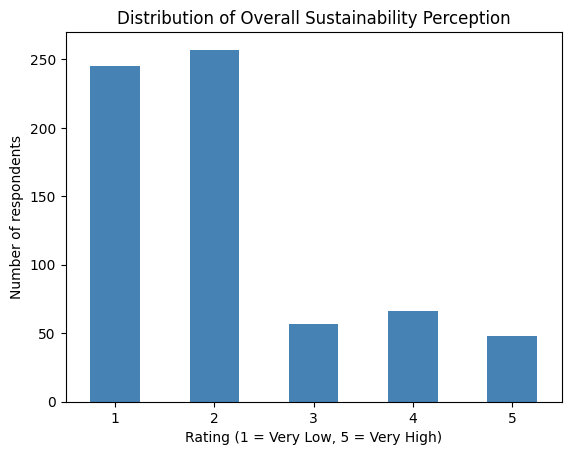

In [ ]:
df["overall_perception"].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Distribution of Overall Sustainability Perception")
plt.xlabel("Rating (1 = Very Low, 5 = Very High)")
plt.ylabel("Number of respondents")
plt.xticks(rotation=0)
plt.show()

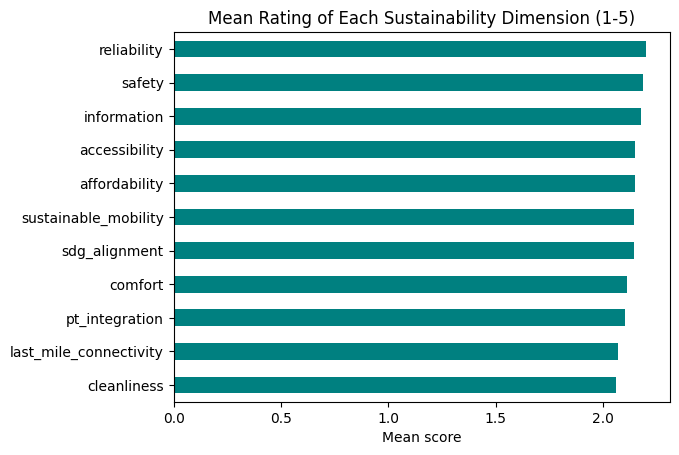

In [ ]:
df[predictors].mean().sort_values().plot(kind="barh", color="teal")
plt.title("Mean Rating of Each Sustainability Dimension (1-5)")
plt.xlabel("Mean score")
plt.show()

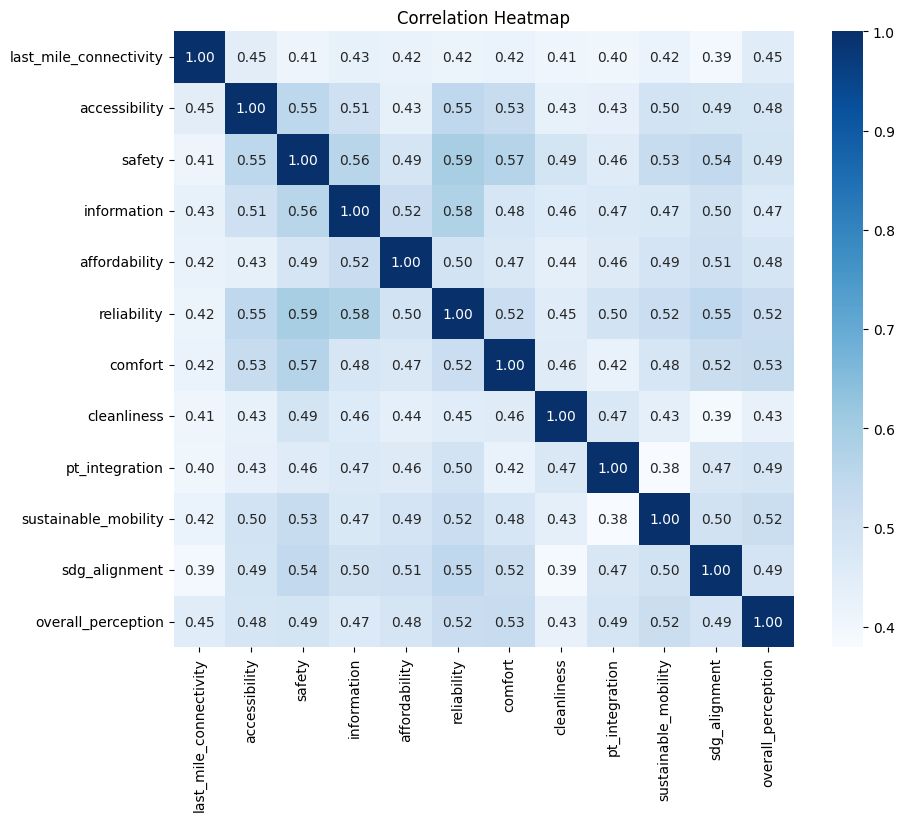

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[predictors + ["overall_perception"]].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
df["has_used"] = df["usage_frequency"] != "I have not used Pune Metro yet"

print(df["has_used"].value_counts())
print("\nMean overall perception by group:")
print(df.groupby("has_used")["overall_perception"].agg(["count", "mean", "std"]).round(2))

print("\nMean of each dimension by group:")
print(df.groupby("has_used")[predictors].mean().round(2).T)

has_used
True     580
False     93
Name: count, dtype: int64

Mean overall perception by group:
          count  mean   std
has_used                   
False        93  2.09  1.23
True        580  2.14  1.21

Mean of each dimension by group:
has_used                False  True 
last_mile_connectivity   2.10   2.07
accessibility            1.88   2.19
safety                   1.91   2.23
information              1.86   2.23
affordability            1.81   2.20
reliability              1.90   2.25
comfort                  1.87   2.15
cleanliness              1.88   2.09
pt_integration           2.02   2.11
sustainable_mobility     2.09   2.16
sdg_alignment            2.10   2.15


In [ ]:
X = df[predictors]
y = df["overall_perception"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nColumns in X:")
print(list(X.columns))

X shape: (673, 11)
y shape: (673,)

Columns in X:
['last_mile_connectivity', 'accessibility', 'safety', 'information', 'affordability', 'reliability', 'comfort', 'cleanliness', 'pt_integration', 'sustainable_mobility', 'sdg_alignment']


In [ ]:
print("Target in X?      ", "overall_perception" in X.columns)
print("Helper col in X?  ", "has_used" in X.columns)
print("Non-numeric in X? ", (X.dtypes == "object").any())
print("Missing in X:     ", X.isnull().sum().sum())
print("Missing in y:     ", y.isnull().sum())

Target in X?       False
Helper col in X?   False
Non-numeric in X?  False
Missing in X:      0
Missing in y:      0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTarget mean (train):", round(y_train.mean(), 2))
print("Target mean (test): ", round(y_test.mean(), 2))

Train: (538, 11) | Test: (135, 11)

Target mean (train): 2.11
Target mean (test):  2.22


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_r2   = r2_score(y_test, lr_pred)
lr_mae  = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print("Linear Regression (test set)")
print("R²  :", round(lr_r2, 3))
print("MAE :", round(lr_mae, 3))
print("RMSE:", round(lr_rmse, 3))

Linear Regression (test set)
R²  : 0.377
MAE : 0.724
RMSE: 0.945


In [ ]:
coef = pd.Series(lr.coef_, index=X.columns).sort_values(ascending=False)
print(coef.round(3))

comfort                   0.168
sustainable_mobility      0.146
pt_integration            0.134
sdg_alignment             0.111
last_mile_connectivity    0.094
affordability             0.090
reliability               0.065
safety                    0.050
cleanliness               0.048
accessibility             0.027
information               0.006
dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=42
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_r2   = r2_score(y_test, rf_pred)
rf_mae  = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest (test set)")
print("R²  :", round(rf_r2, 3))
print("MAE :", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))

Random Forest (test set)
R²  : 0.326
MAE : 0.772
RMSE: 0.983


In [ ]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(rf_importance.round(3))
print("\nSum of importances:", round(rf_importance.sum(), 3))

sdg_alignment             0.241
comfort                   0.210
sustainable_mobility      0.138
pt_integration            0.069
safety                    0.062
cleanliness               0.058
accessibility             0.049
affordability             0.045
last_mile_connectivity    0.045
reliability               0.043
information               0.041
dtype: float64

Sum of importances: 1.0


In [ ]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42),
}

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

rows = []
for name, model in models.items():
    cv = cross_validate(model, X, y, cv=kf, scoring=scoring)
    rows.append({
        "Model": name,
        "R2 mean": cv["test_r2"].mean(),
        "R2 std": cv["test_r2"].std(),
        "MAE mean": -cv["test_mae"].mean(),
        "RMSE mean": -cv["test_rmse"].mean(),
    })

comparison = pd.DataFrame(rows).round(3)
comparison

,Model,R2 mean,R2 std,MAE mean,RMSE mean
0,Linear Regression,0.428,0.054,0.710,0.911
1,Random Forest,0.410,0.057,0.741,0.925


In [ ]:
for name, model in models.items():
    cv = cross_validate(model, X, y, cv=kf, scoring="r2")
    print(name, "->", np.round(cv["test_score"], 3))

Linear Regression -> [0.377 0.469 0.349 0.485 0.462]
Random Forest -> [0.323 0.481 0.367 0.434 0.446]


In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=30,
                              random_state=42, scoring="r2")

perm_df = pd.DataFrame({
    "factor": X.columns,
    "perm_importance": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("perm_importance", ascending=False)

print(perm_df.round(4).to_string(index=False))

                factor  perm_importance    std
  sustainable_mobility           0.0597 0.0152
        pt_integration           0.0501 0.0149
           cleanliness           0.0340 0.0177
               comfort           0.0296 0.0237
           reliability           0.0234 0.0101
last_mile_connectivity           0.0145 0.0137
         sdg_alignment           0.0013 0.0210
         affordability          -0.0048 0.0076
           information          -0.0050 0.0089
         accessibility          -0.0061 0.0092
                safety          -0.0106 0.0090


In [ ]:
def avg_perm_importance(X_in, y_in, n_splits=20):
    results = []
    for seed in range(n_splits):
        Xtr, Xte, ytr, yte = train_test_split(X_in, y_in, test_size=0.2, random_state=seed)
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=seed)
        m.fit(Xtr, ytr)
        p = permutation_importance(m, Xte, yte, n_repeats=10, random_state=seed, scoring="r2")
        results.append(p.importances_mean)
    return pd.Series(np.mean(results, axis=0), index=X_in.columns)

imp_all = avg_perm_importance(X, y)
imp_all = imp_all.sort_values(ascending=False)
print(imp_all.round(4))

sustainable_mobility      0.0816
comfort                   0.0724
pt_integration            0.0550
accessibility             0.0489
reliability               0.0326
sdg_alignment             0.0260
cleanliness               0.0209
last_mile_connectivity    0.0142
affordability             0.0118
information               0.0066
safety                   -0.0044
dtype: float64


In [ ]:
# Negative values (shuffling slightly helped) are treated as 0 before converting to shares
pos = imp_all.clip(lower=0)
share = (pos / pos.sum() * 100).round(1)
print(share)

sustainable_mobility      22.1
comfort                   19.6
pt_integration            14.9
accessibility             13.2
reliability                8.8
sdg_alignment              7.0
cleanliness                5.6
last_mile_connectivity     3.8
affordability              3.2
information                1.8
safety                     0.0
dtype: float64


In [ ]:
# (a) users only
mask = df["has_used"]
imp_users = avg_perm_importance(X[mask], y[mask]).sort_values(ascending=False)

# (b) without sdg_alignment
X_nosdg = X.drop(columns=["sdg_alignment"])
imp_nosdg = avg_perm_importance(X_nosdg, y).sort_values(ascending=False)

print("USERS ONLY (n=580)")
print(imp_users.round(4))
print("\nWITHOUT sdg_alignment")
print(imp_nosdg.round(4))

USERS ONLY (n=580)
accessibility             0.1399
sustainable_mobility      0.0645
comfort                   0.0577
pt_integration            0.0386
reliability               0.0348
sdg_alignment             0.0202
affordability             0.0181
last_mile_connectivity    0.0131
cleanliness               0.0096
information               0.0045
safety                    0.0010
dtype: float64

WITHOUT sdg_alignment
comfort                   0.0979
sustainable_mobility      0.0790
accessibility             0.0600
pt_integration            0.0565
reliability               0.0450
affordability             0.0191
cleanliness               0.0183
last_mile_connectivity    0.0109
information               0.0071
safety                   -0.0010
dtype: float64
